# Road Damage Detection - Part 1: Setup, Data, EDA
Run on Kaggle with **Accelerator = GPU** and **Internet = On**.
Add your Roboflow key in *Add-ons > Secrets* with the name `ROBOFLOW_API_KEY`.

In [1]:
!pip install -q ultralytics roboflow gradio
import torch, ultralytics
print('Ultralytics:', ultralytics.__version__)
print('CUDA:', torch.cuda.is_available(), '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'no GPU')

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.190
CUDA: True | Tesla T4


## 1. Download dataset from Roboflow
Open the dataset page on Roboflow, go to *Download Dataset > YOLOv8 format*, and copy the workspace / project / version values.

In [2]:
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

API_KEY = UserSecretsClient().get_secret('ROBOFLOW_API_KEY')

rf = Roboflow(api_key=API_KEY)
project = rf.workspace("mazen-ayad").project("road-damage-l1ju7-g2jni")
version = project.version(1)
dataset = version.download("yolov8", location="/kaggle/working/road-damage")
print(dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/road-damage in yolov8:: 100%|██████████| 13518/13518 [00:03<00:00, 4388.00it/s] 


/kaggle/working/road-damage


## 2. Fix data.yaml (absolute paths) and read class names

In [3]:
import yaml
from pathlib import Path

DATA_DIR = Path(dataset.location)
cfg = yaml.safe_load(open(DATA_DIR / 'data.yaml'))
names = cfg['names']
names = list(names.values()) if isinstance(names, dict) else list(names)

cfg.update(path=str(DATA_DIR), train='train/images', val='valid/images', test='test/images')
yaml.safe_dump(cfg, open(DATA_DIR / 'data.yaml', 'w'))
DATA_YAML = str(DATA_DIR / 'data.yaml')

print('Classes:', len(names))
for i, n in enumerate(names):
    print(i, n)

Classes: 7
0 alligator
1 block
2 crack
3 edge
4 longitudinal
5 pothole
6 transverse


## 3. EDA: images and boxes per split / class

split  images  empty_images  boxes
train    4930             0  15027
valid    1146             0   3588
 test     681             0   2004


,train,valid,test
alligator,4337,1001,577
block,305,86,47
crack,1797,226,93
edge,21,1,0
longitudinal,2008,548,311
pothole,6075,1600,909
transverse,484,126,67


<Axes: title={'center': 'Boxes per class and split'}>

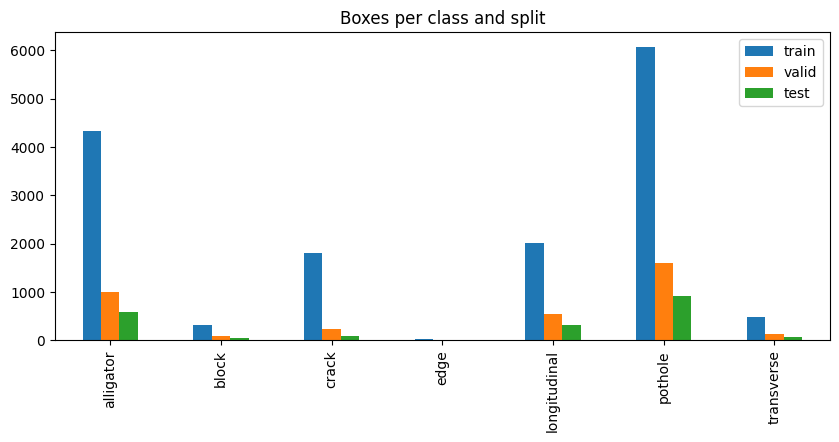

In [4]:
import pandas as pd
from collections import Counter

def count_split(split):
    c, n_img, n_empty = Counter(), 0, 0
    for f in (DATA_DIR / split / 'labels').glob('*.txt'):
        n_img += 1
        lines = [l for l in f.read_text().splitlines() if l.strip()]
        if not lines:
            n_empty += 1
        for l in lines:
            c[int(l.split()[0])] += 1
    return n_img, n_empty, c

rows, per_class = [], {}
for split in ['train', 'valid', 'test']:
    n_img, n_empty, c = count_split(split)
    rows.append(dict(split=split, images=n_img, empty_images=n_empty, boxes=sum(c.values())))
    per_class[split] = [c.get(i, 0) for i in range(len(names))]

print(pd.DataFrame(rows).to_string(index=False))
df_cls = pd.DataFrame(per_class, index=names)
display(df_cls)
df_cls.plot(kind='bar', figsize=(10, 4), title='Boxes per class and split')

## 4. Sample training images with ground-truth boxes

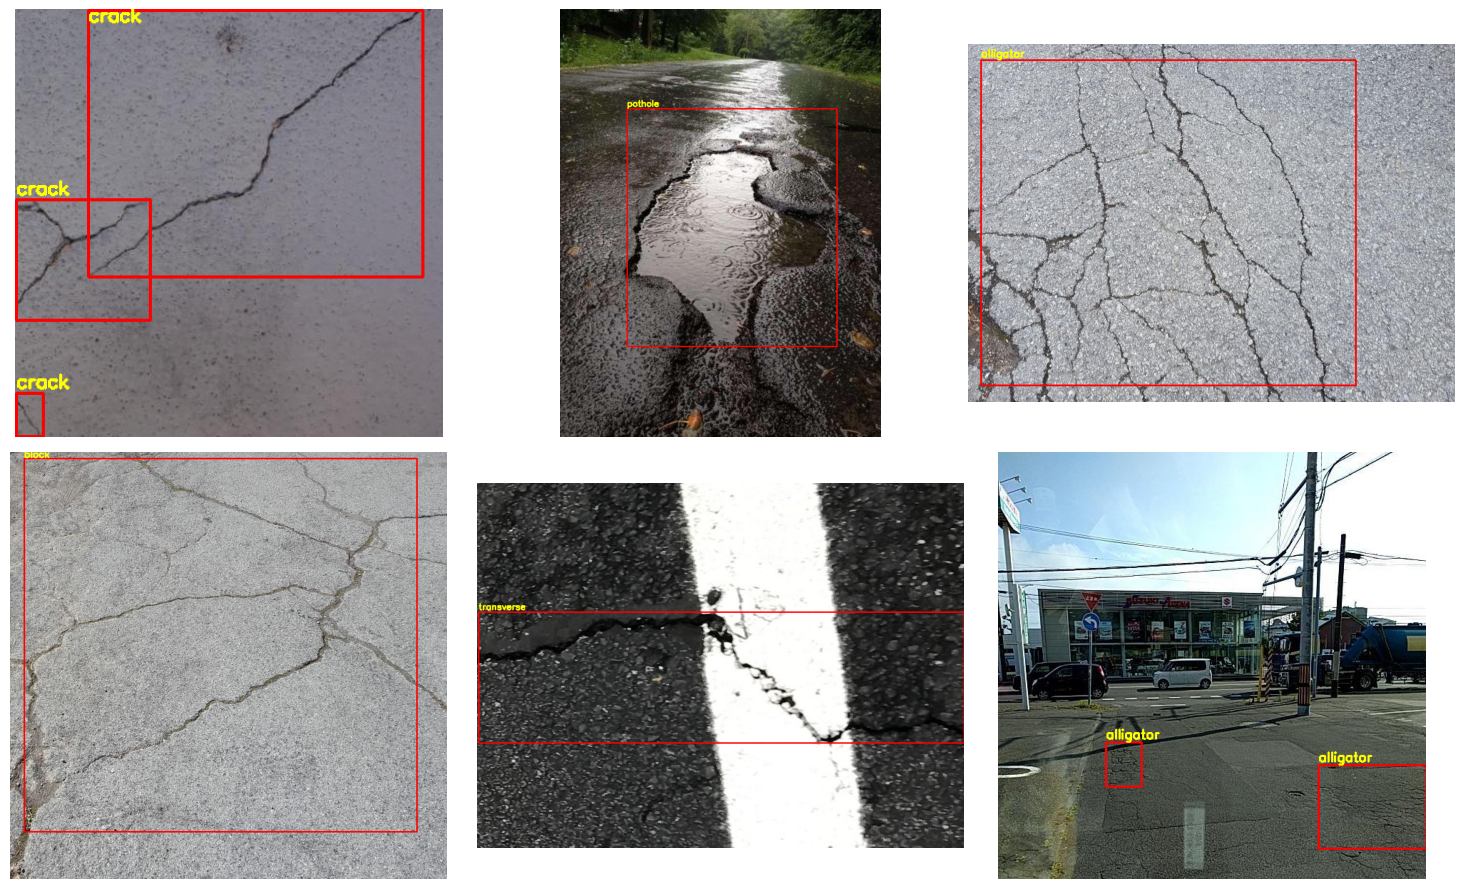

In [5]:
import cv2, random
import matplotlib.pyplot as plt

imgs = sorted((DATA_DIR / 'train' / 'images').glob('*'))
random.seed(42)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, p in zip(axes.ravel(), random.sample(imgs, 6)):
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    lbl = DATA_DIR / 'train' / 'labels' / (p.stem + '.txt')
    for l in lbl.read_text().splitlines():
        if not l.strip():
            continue
        k, x, y, bw, bh = l.split()[:5]
        x, y, bw, bh = float(x) * w, float(y) * h, float(bw) * w, float(bh) * h
        x1, y1, x2, y2 = int(x - bw / 2), int(y - bh / 2), int(x + bw / 2), int(y + bh / 2)
        cv2.rectangle(im, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cv2.putText(im, names[int(k)], (x1, max(y1 - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 0), 2)
    ax.imshow(im)
    ax.axis('off')
plt.tight_layout()
plt.show()